In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import tensorflow   as  tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras import layers
from tensorflow.keras.layers import LSTM, Dense

In [16]:
data = yf.download("^NSEI", start="2015-01-01")

data = data[['Close']]
data.head()

[*********************100%***********************]  1 of 1 completed


Price,Close
Ticker,^NSEI
Date,
2015-01-02,8395.450195
2015-01-05,8378.400391
2015-01-06,8127.350098
2015-01-07,8102.100098
2015-01-08,8234.599609


In [17]:
scaler=MinMaxScaler()
prices=scaler.fit_transform(data)

In [18]:
x=[]
y=[]
for i in range(60,len(prices)):
    x.append(prices[i-60:i])
    y.append(prices[i])
x=np.array(x)
y=np.array(y)

In [19]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, shuffle=False
)

In [ ]:
lstm_model = tf.keras.Sequential([
    layers.LSTM(32, input_shape=(60,1)),
    layers.Dense(1)
])

lstm_model.compile(optimizer='adam', loss='mse', metrics=['mae'])

lstm_model.fit(x_train, y_train, epochs=10, batch_size=32)

c:\Users\VIVEK V\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 0.0179
Epoch 2/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - loss: 2.7920e-04
Epoch 3/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 2.6311e-04
Epoch 4/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 2.5590e-04
Epoch 5/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 2.4024e-04
Epoch 6/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 2.2972e-04
Epoch 7/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 2.2376e-04
Epoch 8/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 2.1489e-04
Epoch 9/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 2.0888e-04
Epoch 10/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 1.9600e-04


In [ ]:
gru_model = tf.keras.Sequential([
    layers.GRU(32, input_shape=(60,1)),
    layers.Dense(1)
])

gru_model.compile(optimizer='adam', loss='mse', metrics=['mae'])

gru_model.fit(x_train, y_train, epochs=10, batch_size=32)

Epoch 1/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - loss: 0.0170
Epoch 2/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 4s 58ms/step - loss: 1.5000e-04
Epoch 3/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - loss: 9.3881e-05
Epoch 4/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 7s 82ms/step - loss: 9.0064e-05
Epoch 5/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 11s 87ms/step - loss: 8.6758e-05
Epoch 6/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - loss: 8.3904e-05
Epoch 7/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 5s 64ms/step - loss: 8.1114e-05
Epoch 8/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - loss: 7.8501e-05
Epoch 9/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - loss: 7.7504e-05
Epoch 10/10
72/72 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 7.4102e-05


In [27]:
lstm_pred = lstm_model.predict(x_test)
gru_pred = gru_model.predict(x_test)

lstm_pred = scaler.inverse_transform(lstm_pred)
gru_pred = scaler.inverse_transform(gru_pred)

actual = scaler.inverse_transform(y_test)

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step


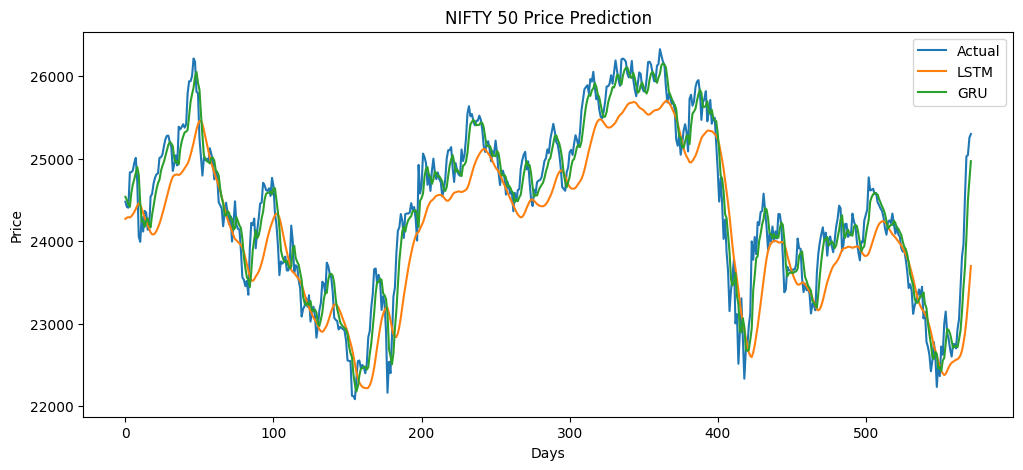

In [28]:
plt.figure(figsize=(12,5))

plt.plot(actual, label='Actual')
plt.plot(lstm_pred, label='LSTM')
plt.plot(gru_pred, label='GRU')

plt.title('NIFTY 50 Price Prediction')
plt.xlabel('Days')
plt.ylabel('Price')
plt.legend()
plt.show()

In [32]:
print("LSTM RMSE:", np.sqrt(mean_squared_error(actual, lstm_pred)))
print("GRU RMSE:", np.sqrt(mean_squared_error(actual, gru_pred)))

LSTM RMSE: 507.4706316199787
GRU RMSE: 247.87180879778236
